In [4]:
# ! pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 56.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [catboost]1/2 [catboost]


In [5]:
import pandas as pd
import os
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error, mean_absolute_error
import numpy as np
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostRegressor
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

In [6]:
os.getcwd()

'/home/kvs/HSE/BDA/ms/2_sem/IMDBresearch/part_4_ml'

Для последующего построения предсказательных моделей нами был использован датасет, полученный по итогам проведения этапа EDA. Также сразу была определена целевая переменная - worldwide gross (кассовые сборы):

In [7]:
df = pd.read_csv(f'{os.getcwd()}/data_after_eda.csv')
df = df.iloc[:, 1:]

target = 'worldwide_gross'

Для устранения проблемы мультиколлинеарности нами была осуществлена проверка на кросс-корреляцию между рассматриваемыми числовыми признаками: признаки, продемонстрировавшие корреляцию между собой были удалены на основании логики их расчета

In [8]:
df.select_dtypes(['int', 'float']).corr() > 0.9
df = df.drop(columns=['profit_or_loss', 'p&l_rate'])

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1455 entries, 0 to 1454
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   title              1455 non-null   object 
 1   average_rating     1455 non-null   float64
 2   director           1455 non-null   object 
 3   writer             1455 non-null   object 
 4   metascore          1455 non-null   int64  
 5   cast               1455 non-null   object 
 6   country_of_origin  1455 non-null   object 
 7   languages          1455 non-null   object 
 8   runtime            1455 non-null   int64  
 9   genre              1455 non-null   object 
 10  budget             1455 non-null   int64  
 11  worldwide_gross    1455 non-null   int64  
 12  release_year       1455 non-null   int64  
 13  lang_cnt           1455 non-null   int64  
 14  country_cnt        1455 non-null   int64  
 15  coproduction       1455 non-null   int64  
dtypes: float64(1), int64(8),

Построили модель линейной регресии на числовых признаках данного датасета (не преобразовывая категориальные данные в числовые):

In [10]:
numeric_columns = df.select_dtypes(include=['int', 'float']).columns.tolist()
numeric_columns


['average_rating',
 'metascore',
 'runtime',
 'budget',
 'worldwide_gross',
 'release_year',
 'lang_cnt',
 'country_cnt',
 'coproduction']

In [12]:
# задаем целевую переменную
y = df['worldwide_gross']

# задаем числовые признаки
X = df[['average_rating', 'metascore', 'runtime', 'budget', 'release_year', 'lang_cnt', 'country_cnt', 'coproduction']]

# масштабируем
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# разделяем
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# задаем линейную регрессию
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# метрики
print("RMSE:", rmse)
print("MAE:", mae)
print("R^2:", r2)

# коэффициенты
feature_names = X.columns
coefs = model.coef_
for name, coef in zip(feature_names, coefs):
    print(f"{name}: {coef:.4f}")

RMSE: 133648938.839786
MAE: 78980810.83315349
R^2: 0.628383250340194
average_rating: 36750058.6300
metascore: 5199872.1420
runtime: -6542850.5457
budget: 201157217.8404
release_year: 5598194.1970
lang_cnt: 2304124.6288
country_cnt: -14681360.2492
coproduction: 6282603.2544


Выводы:<br>
MAE составила около 79 млн дол., RMSE — около 134 млн дол. Коэффициент детерминации равен 0.63, что указывает на то, что модель объясняет около 63% дисперсии целевой переменной.<br>
Наибольший вклад в предсказание вносит бюджет фильма — это самый значимый и положительный фактор. Также положительное влияние оказывают: оценка зрителей (average_rating), оценка критиков (metascore), год выпуска (release_year)и сопродюсирование (coproduction).<br>
Продолжительность фильма (runtime) и количество стран (country_cnt) оказывают отрицательное влияние на предсказания.
Количество языков перевода (lang_cnt) имеет положительный, но сравнительно небольшой эффект.<br>

Попробуем построить модель линейной регрессии с преобразованием категориальных данных и посмотрим на результаты:

Ввиду того, что в ячейках содержалось сразу несколько категорий, использовать метод get_dummies к колонкам не представлялось возможным, вследствие чего нами было принято решение сначала разделить информацию на столбцы с кодированием, а затем добавить их к исходному датасету, удалив столбцы с полным описанием всех категорий, к которым относился фильм.

In [13]:
dir = df['director'].str.strip().str.get_dummies(sep=',')
wr = df['writer'].str.strip().str.get_dummies(sep=',')
cast = df['cast'].str.strip().str.get_dummies(sep=',')
coo = df['country_of_origin'].str.strip().str.get_dummies(sep=',')
lang = df['languages'].str.strip().str.get_dummies(sep=',')
genre = df['genre'].str.strip().str.get_dummies(sep=',')

In [14]:
dir_col = ['director_' + i for i in list(dir.columns)]
dir = dir.rename(columns=dict(zip(dir.columns, dir_col)))

wr_col = ['writer_' + i for i in list(wr.columns)]
wr = wr.rename(columns=dict(zip(wr.columns, wr_col)))

cast_col = ['cast_' + i for i in list(cast.columns)]
cast = cast.rename(columns=dict(zip(cast.columns, cast_col)))

coo_col = ['coo_' + i for i in list(coo.columns)]
coo = coo.rename(columns=dict(zip(coo.columns, coo_col)))

lang_col = ['lang_' + i for i in list(lang.columns)]
lang = lang.rename(columns=dict(zip(lang.columns, lang_col)))

genre_col = ['genre_' + i for i in list(genre.columns)]
genre = genre.rename(columns=dict(zip(genre.columns, genre_col)))

In [15]:
df = df.drop(columns=['director','writer', 'cast', 'country_of_origin', 'languages','genre', 'title'])

In [16]:
df.head()

,average_rating,metascore,runtime,budget,worldwide_gross,release_year,lang_cnt,country_cnt,coproduction
0,9.3,82,142,25000000,29332133,1994,1,1,0
1,9.2,100,175,6000000,250342198,1978,3,1,0
2,9.0,84,152,185000000,1009053678,2008,2,2,1
3,9.0,95,195,22000000,322161245,1993,5,1,0
4,9.0,97,96,350000,2945,1957,1,1,0


После подготовки датасета мы разделили его на части - столбец с данными о целевой переменной и датасет с независимыми переменными (признаками)

In [17]:
X = df.drop(columns=target)
y = df[target]

Для корректного построения модели приведем числовые признаки к единому виду с помощью функции Standard Scaler и применим ее к датасету с независимыми переменными

In [18]:
scale = StandardScaler()
X_sc = scale.fit_transform(X)

In [19]:
X_sc = pd.DataFrame(data=X_sc, columns=X.columns)
X = pd.concat([X_sc, dir, wr, cast, coo, lang, genre], axis = 1)

In [20]:
X.head()

,average_rating,metascore,runtime,budget,release_year,lang_cnt,country_cnt,coproduction,director_Aaron Sorkin,director_Abhishek Chaubey,...,genre_Documentary,genre_Drama,genre_Family,genre_Fantasy,genre_Film-Noir,genre_Horror,genre_Mystery,genre_Romance,genre_Sci-Fi,genre_Thriller
0,4.728921,0.688583,0.860424,-0.124791,-0.164135,-0.740620,-0.600930,-0.815328,0,0,...,0,1,0,0,0,0,0,0,0,0
1,4.449143,2.126011,2.221202,-0.534754,-0.907386,0.806547,-0.600930,-0.815328,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3.889587,0.848297,1.272781,3.327530,0.486210,0.032964,0.290358,1.226500,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3.889587,1.726726,3.045917,-0.189522,-0.210588,2.353713,-0.600930,-0.815328,0,0,...,0,0,0,0,0,0,0,0,0,0
4,3.889587,1.886440,-1.036419,-0.656664,-1.882904,-0.740620,-0.600930,-0.815328,0,0,...,0,0,0,0,0,0,0,0,0,0


Мы разделили выборку на тестовую и обучающую в процентном соотношении 20 к 80 и зафиксировали ее результат с помощью определения random state

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state = 42)

In [22]:
X_train_OLS = X_train.copy()
X_test_OLS = X_test.copy()
X_train_OLS = sm.add_constant(X_train_OLS)
X_test_OLS = sm.add_constant(X_test_OLS)
model = sm.OLS(y_train, X_train_OLS).fit()
model.summary()

/home/kvs/HSE/BDA/.venv/lib/python3.13/site-packages/statsmodels/regression/linear_model.py:1795: RuntimeWarning: divide by zero encountered in divide
  return 1 - (np.divide(self.nobs - self.k_constant, self.df_resid)
/home/kvs/HSE/BDA/.venv/lib/python3.13/site-packages/statsmodels/regression/linear_model.py:1795: RuntimeWarning: invalid value encountered in scalar multiply
  return 1 - (np.divide(self.nobs - self.k_constant, self.df_resid)
/home/kvs/HSE/BDA/.venv/lib/python3.13/site-packages/statsmodels/regression/linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
/home/kvs/HSE/BDA/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1527: RuntimeWarning: invalid value encountered in multiply
  cov_p = self.normalized_cov_params * scale


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        worldwide_gross   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                    nan
Method:                 Least Squares   F-statistic:                       nan
Date:                Mon, 23 Jun 2025   Prob (F-statistic):                nan
Time:                        19:51:02   Log-Likelihood:                 14715.
No. Observations:                1164   AIC:                        -2.710e+04
Df Residuals:                       0   BIC:                        -2.121e+04
Df Model:                        1163                                         
Covariance Type:            nonrobust                                         
===========================================================================================================
                                              coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
const                                     9.66e+07        inf          0        nan         nan         nan
average_rating                           4.495e+07        inf          0        nan         nan         nan
metascore                                5.589e+06        inf          0        nan         nan         nan
runtime                                  -7.85e+06        inf         -0        nan         nan         nan
budget                                   1.771e+08        inf          0        nan         nan         nan
release_year                             1.317e+07        inf          0        nan         nan         nan
lang_cnt                                 8.595e+06        inf          0        nan         nan         nan
country_cnt                              -8.79e+06        inf         -0        nan         nan         nan
coproduction                             1.277e+07        inf          0        nan         nan         nan
director_Aaron Sorkin                   -1.221e+07        inf         -0        nan         nan         nan
director_Abhishek Chaubey                3.882e+06        inf          0        nan         nan         nan
director_Adam McKay                     -2.565e+07        inf         -0        nan         nan         nan
director_Adam Shankman                  -1.971e-07        inf         -0        nan         nan         nan
director_Adrian Lyne                     1.627e-08        inf          0        nan         nan         nan
director_Agnieszka Holland              -1.716e-07        inf         -0        nan         nan         nan
director_Akhtem Seitablaev              -2.604e-08        inf         -0        nan         nan         nan
director_Akira Kurosawa                  7.269e+06        inf          0        nan         nan         nan
director_Alain Gsponer                   5.498e+06        inf          0        nan         nan         nan
director_Alan J. Pakula                  1.186e+06        inf          0        nan         nan         nan
director_Alan Parker                    -1.972e+07        inf         -0        nan         nan         nan
director_Alejandro Amenábar               1.52e+07        inf          0        nan         nan         nan
director_Alejandro G. Iñárritu          -7.311e+06        inf         -0        nan         nan         nan
director_Alejandro Jodorowsky           -3.644e+06        inf         -0        nan         nan         nan
director_Alejandro Monteverde            -8.19e+05        inf         -0        nan         nan         nan
director_Alex Garland                   -7.482e+06        inf         -0        nan         nan         nan
director_Alex Gibney                     5.446e+06        i

Далее мы построили модель линейной регрессии, обучили ее на обучающей выборке и построили предсказание на основании данных из тестовой выборки. Метрики, а именно коэффициент детерминации и среднеквадратическая ошибка, указали на то, что модель переобучилась вследствие большого количества признаков и чрезмерного подстраивания под них. На основании полученных результатов можно сделать вывод, что согласно разработанной модели наибольшую значимость (коэффициентную) для определения успеха масштабности кассовых сборов имело наличие в составе актеров Мишель Родригез, Джованни Рибиси, Стивена Ланга и Сигурни Уивер, в роли директора - Джеймса Кэмерона.

In [23]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
print(f'R^2 для обучающей выборки равен {r2_score(y_train, y_pred_train)}')
print(f'R^2 для тестовой выборки равен {r2_score(y_test, y_pred_test)}')
print(f'MSE для обучающей выборки равна {mean_squared_error(y_train, y_pred_train)}')
print(f'MSE для тестовой выборки равна {mean_squared_error(y_test, y_pred_test)}')
print(f'RMSE для тестовой выборки равна {np.sqrt(mean_squared_error(y_test, y_pred_test))}')
LR_res = pd.DataFrame(data=(zip(X.columns, model.coef_)), columns=['params', 'coefficients'])
display(LR_res.sort_values('coefficients', ascending=False).head(7))

R^2 для обучающей выборки равен 1.0
R^2 для тестовой выборки равен 0.6192562467965597
MSE для обучающей выборки равна 7.341411556564085e-12
MSE для тестовой выборки равна 1.830073514980965e+16
RMSE для тестовой выборки равна 135280209.74928167


,params,coefficients
6053,cast_ Michelle Rodriguez,3.525497e+08
4591,cast_ Giovanni Ribisi,3.231400e+08
6997,cast_ Stephen Lang,2.550895e+08
270,director_James Cameron,2.497344e+08
6926,cast_ Sigourney Weaver,2.492841e+08
8524,cast_Zoe Saldana,2.211252e+08
4599,cast_ Gloria Stuart,2.012614e+08


Для улучшения качества прогнозовы мы решили построить модели Ridge и Lasso,  методика действия которых основана на приписывании штрафов за некорректное отражение коэффициентов, что позволяет обнулить незначимые из независимых переменных, а также улучшить качество прогноза.

In [24]:
model = Ridge(alpha=25)
model.fit(X_train, y_train)
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
print(f'R^2 для обучающей выборки равен {r2_score(y_train, y_pred_train)}')
print(f'R^2 для тестовой выборки равен {r2_score(y_test, y_pred_test)}')
print(f'MSE для обучающей выборки равна {mean_squared_error(y_train, y_pred_train)}')
print(f'MSE для тестовой выборки равна {mean_squared_error(y_test, y_pred_test)}')
print(f'RMSE для тестовой выборки равна {np.sqrt(mean_squared_error(y_test, y_pred_test))}')
Ridge_res = pd.DataFrame(data=(zip(X.columns, model.coef_)), columns=['params', 'coefficients'])
display(Ridge_res.sort_values('coefficients', ascending=False).head(7))

R^2 для обучающей выборки равен 0.8310525445891038
R^2 для тестовой выборки равен 0.6632658021853259
MSE для обучающей выборки равна 1.0894365742288508e+16
MSE для тестовой выборки равна 1.6185382736396992e+16
RMSE для тестовой выборки равна 127221785.62021911


,params,coefficients
3,budget,1.771520e+08
270,director_James Cameron,8.772479e+07
2463,writer_James Cameron,7.247864e+07
6926,cast_ Sigourney Weaver,6.963022e+07
6997,cast_ Stephen Lang,6.892641e+07
8524,cast_Zoe Saldana,6.631051e+07
4591,cast_ Giovanni Ribisi,5.675738e+07


In [25]:
model = Lasso(alpha=1000)
model.fit(X_train, y_train)
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
print(f'R^2 для обучающей выборки равен {r2_score(y_train, y_pred_train)}')
print(f'R^2 для тестовой выборки равен {r2_score(y_test, y_pred_test)}')
print(f'MSE для обучающей выборки равна {mean_squared_error(y_train, y_pred_train)}')
print(f'MSE для тестовой выборки равна {mean_squared_error(y_test, y_pred_test)}')
print(f'RMSE для тестовой выборки равна {np.sqrt(mean_squared_error(y_test, y_pred_test))}')
Lasso_res = pd.DataFrame(data=(zip(X.columns, model.coef_)), columns=['params', 'coefficients'])
display(Lasso_res.sort_values('coefficients', ascending=False).head(7))

/home/kvs/HSE/BDA/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.749e+16, tolerance: 7.506e+15
  model = cd_fast.enet_coordinate_descent(


R^2 для обучающей выборки равен 0.999986914540205
R^2 для тестовой выборки равен 0.5335662576000846
MSE для обучающей выборки равна 843799538532.1753
MSE для тестовой выборки равна 2.241948899430626e+16
RMSE для тестовой выборки равна 149731389.47564155


,params,coefficients
6053,cast_ Michelle Rodriguez,9.562587e+08
1088,writer_ Erik Sommers,9.513295e+08
374,director_Kelsey Mann,9.495694e+08
3548,cast_ Billy Zane,9.106092e+08
1233,writer_ Jack Epps Jr.,6.866318e+08
1413,writer_ Kai Bird,5.740812e+08
270,director_James Cameron,5.734722e+08


Попробуем также модель CatBoost и посмотрим на результаты:

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_cb = CatBoostRegressor(iterations=1000, learning_rate=0.1, depth=6, verbose=100, early_stopping_rounds=30, random_state=42)
model_cb.fit(X_train, y_train, eval_set=(X_test, y_test))

y_pred = model_cb.predict(X_test)
y_pred_train = model_cb.predict(X_train)
y_pred_test= model_cb.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("CatBoost RMSE:", rmse)
print("CatBoost MAE:", mae)
print("CatBoost R²:", r2)

0:	learn: 241971277.0987588	test: 209598443.5384080	best: 209598443.5384080 (0)	total: 5.26ms	remaining: 5.26s
100:	learn: 89294469.5153911	test: 125819660.4809400	best: 125686189.2992803 (97)	total: 511ms	remaining: 4.55s
200:	learn: 70788324.2363692	test: 123497628.0254081	best: 123014402.5530095 (179)	total: 1.13s	remaining: 4.5s
Stopped by overfitting detector  (30 iterations wait)

bestTest = 123014402.6
bestIteration = 179

Shrink model to first 180 iterations.
CatBoost RMSE: 123014401.68825842
CatBoost MAE: 69229296.34349412
CatBoost R²: 0.6851699574460564


In [29]:
print(f'R^2 для обучающей выборки равен {r2_score(y_train, y_pred_train)}')
print(f'R^2 для тестовой выборки равен {r2_score(y_test, y_pred_test)}')
print(f'MSE для обучающей выборки равна {mean_squared_error(y_train, y_pred_train)}')
print(f'MSE для тестовой выборки равна {mean_squared_error(y_test, y_pred_test)}')
print(f'RMSE для тестовой выборки равна {np.sqrt(mean_squared_error(y_test, y_pred_test))}')
print("MAE:", mean_absolute_error(y_test, y_pred))

R^2 для обучающей выборки равен 0.9171966664883356
R^2 для тестовой выборки равен 0.6851699574460564
MSE для обучающей выборки равна 5339469586936354.0
MSE для тестовой выборки равна 1.5132543022720198e+16
RMSE для тестовой выборки равна 123014401.68825842
MAE: 69229296.34349412


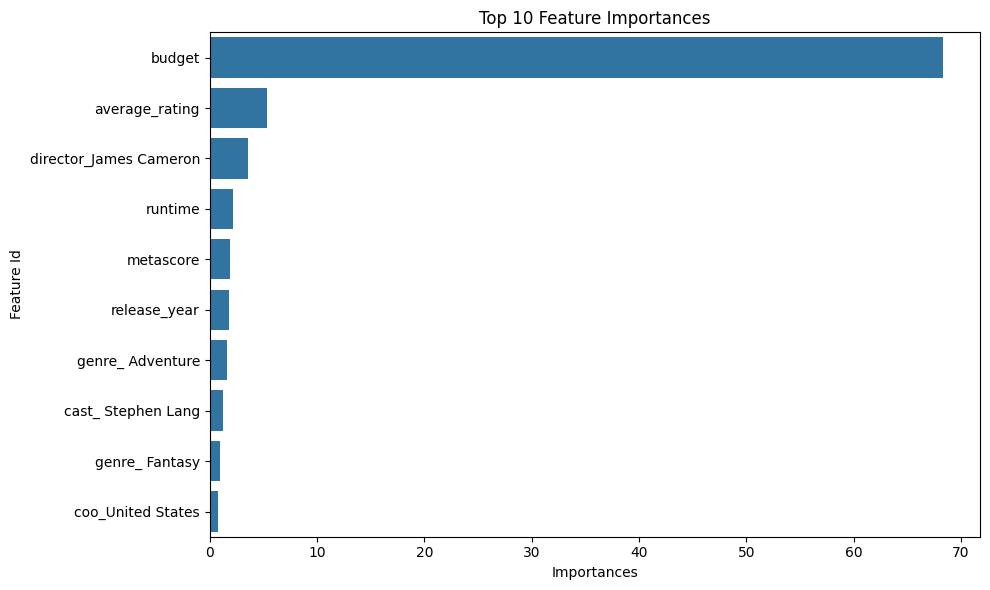

In [60]:
feat_importance = model_cb.get_feature_importance(prettified=True)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importances', y='Feature Id', data=feat_importance.head(10))
plt.title("Top 10 Feature Importances")
plt.tight_layout()
plt.show()

In [67]:
model_cb = CatBoostRegressor(iterations=1000, verbose=0, early_stopping_rounds=30, random_state=42)

pipeline = Pipeline([('model', model_cb)])
param_dist = {'model__depth': randint(4, 10), 'model__learning_rate': uniform(0.03, 0.25), 'model__l2_leaf_reg': randint(1, 10)}

random_search = RandomizedSearchCV(pipeline, param_distributions=param_dist, n_iter=30, scoring='neg_root_mean_squared_error', cv=3, verbose=2, random_state=42, n_jobs=-1)
random_search.fit(X_train, y_train)

print("Лучшие параметры:", random_search.best_params_)


Fitting 3 folds for each of 30 candidates, totalling 90 fits


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:440: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:440: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:440: InconsistentVersionWarning: Trying to unpickl

[CV] END model__depth=5, model__l2_leaf_reg=3, model__learning_rate=0.05499372895450072; total time=   9.6s


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:440: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/parallel.py:135: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/_tags.py:338: DeprecationWarning: The following error was raised: 'CatBoostRegressor' object has no attribute '__sklearn_tags__'. It seems tha

[CV] END model__depth=5, model__l2_leaf_reg=3, model__learning_rate=0.05499372895450072; total time=  10.5s


...

[CV] END model__depth=6, model__l2_leaf_reg=3, model__learning_rate=0.20671433596190428; total time=  23.6s


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:440: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/parallel.py:135: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/_tags.py:338: DeprecationWarning: The following error was raised: 'CatBoostRegressor' object has no attribute '__sklearn_tags__'. It seems tha

[CV] END model__depth=6, model__l2_leaf_reg=3, model__learning_rate=0.22281758667148643; total time=  22.3s


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:440: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/parallel.py:135: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/_tags.py:338: DeprecationWarning: The following error was raised: 'CatBoostRegressor' object has no attribute '__sklearn_tags__'. It seems tha

[CV] END model__depth=6, model__l2_leaf_reg=3, model__learning_rate=0.22281758667148643; total time=  22.6s
[CV] END model__depth=6, model__l2_leaf_reg=3, model__learning_rate=0.22281758667148643; total time=  19.2s
[CV] END model__depth=8, model__l2_leaf_reg=7, model__learning_rate=0.19276925637548611; total time=  32.8s
[CV] END model__depth=7, model__l2_leaf_reg=7, model__learning_rate=0.24250964444744982; total time=  24.4s
[CV] END model__depth=7, model__l2_leaf_reg=7, model__learning_rate=0.24250964444744982; total time=  23.9s
[CV] END model__depth=7, model__l2_leaf_reg=7, model__learning_rate=0.24250964444744982; total time=  24.9s
[CV] END model__depth=8, model__l2_leaf_reg=7, model__learning_rate=0.19276925637548611; total time=  28.7s
[CV] END model__depth=8, model__l2_leaf_reg=7, model__learning_rate=0.19276925637548611; total time=  30.0s
Лучшие параметры: {'model__depth': 4, 'model__l2_leaf_reg': 1, 'model__learning_rate': np.float64(0.16119366506459729)}


In [90]:
best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("CatBoost RMSE:", rmse)
print("MAE:", mae)
print("R^2:", r2)

CatBoost RMSE: 124700360.05837163
MAE: 67573073.17781352
R^2: 0.6764810937334289


Результаты:

Модель линейной регрессии без преобразования категориальных признаков:<br>
RMSE: 133648938.83978602<br>
MAE: 78980810.83315353<br>
R^2: 0.6283832503401939<br>
<br>
Модель линейной регрессии с преобразованием:<br>
R^2 для обучающей выборки равен 1.0<br>
R^2 для тестовой выборки равен 0.6192562467965521<br>
MSE для обучающей выборки равна 1.7457236687151768e-10<br>
MSE для тестовой выборки равна 1.830073514981e+16<br>
RMSE для тестовой выборки равна 135280209.749283<br>
<br>
Модель Ridge:<br>
R^2 для обучающей выборки равен 0.8310525445891044<br>
R^2 для тестовой выборки равен 0.6632658021853104<br>
MSE для обучающей выборки равна 1.0894365742288472e+16<br>
MSE для тестовой выборки равна 1.6185382736397734e+16<br>
RMSE для тестовой выборки равна 127221785.62022203<br>
<br>
Модель Lasso:<br>
R^2 для обучающей выборки равен 0.999986914540205<br>
R^2 для тестовой выборки равен 0.5335662576000838<br>
MSE для обучающей выборки равна 843799538532.1843<br>
MSE для тестовой выборки равна 2.2419488994306296e+16<br>
RMSE для тестовой выборки равна 149731389.47564167<br>
<br>
Модель СatBoostRegressor:<br>
CatBoost RMSE: 124700360.05837163<br>
MAE: 67573073.17781352<br>
R^2: 0.6764810937334289<br>

На основе представленных результатов можно сделать следующий вывод:

Наилучшие результаты среди всех моделей показала модель CatBoostRegressor. Её коэффициент детерминации R^2 на тестовой выборке составил 0.676, что выше, чем у остальных моделей, а RMSE оказался наименьшим — 124.7 млн, что свидетельствует о более точных предсказаниях.

Модель Ridge также продемонстрировала стабильные результаты (R² = 0.663, RMSE ≈ 127.2 млн), однако по обоим показателям уступила CatBoost.

Модели линейной регрессии (с и без преобразования признаков) и особенно Lasso либо переобучились в виду большого числа признаков.


Согласно полученным результатам, на целевую переменную (объем кассовых сборов) значительно воздействие оказывает бюджет фильма, а также наличие в составе директора - Джеймса Кэмерона, в составе актеров - Стивена Ланга, жанр - приключение и фэнтэзи со страной-сопродюсером - США.